
## Business Objective

The objective of this phase is to identify the characteristics associated with high-value customers, strong digital engagement, and reduced churn risk.

Rather than focusing solely on customer demographics, this analysis investigates behavioural and customer experience metrics that are most relevant to customer retention, product adoption, and long-term customer value.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option("display.max_columns", None)

customers = pd.read_csv("../data/customers_clean.csv")
transactions = pd.read_csv("../data/transactions_clean.csv")

In [2]:
#Let's first understand the two variables
customers[["active_products", "churn_probability"]].describe().T

,count,mean,std,min,25%,50%,75%,max
active_products,48723.0,2.095253,1.178333,1.000000,1.000000,2.000000,3.000000,5.000000
churn_probability,48723.0,0.342922,0.067073,0.114319,0.302938,0.353972,0.392724,0.500641


In [3]:
correlation = customers["active_products"].corr(
    customers["churn_probability"]
)

print(f"Correlation: {correlation:.3f}")

Correlation: -0.876


In [4]:
churn_by_products = (
    customers
    .groupby("active_products", observed=True)
    .agg(
        Average_Churn=("churn_probability", "mean"),
        Customers=("customer_id", "count")
    )
    .round(3)
)

churn_by_products

,Average_Churn,Customers
active_products,,
1,0.397,19576
2,0.348,14653
3,0.298,7197
4,0.248,4871
5,0.198,2426


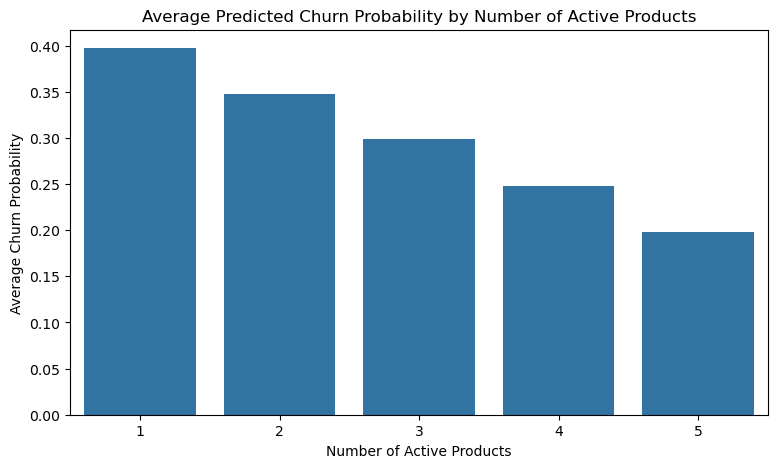

In [5]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=customers,
    x="active_products",
    y="churn_probability",
    estimator="mean",
    errorbar=None
)

plt.title("Average Predicted Churn Probability by Number of Active Products")
plt.xlabel("Number of Active Products")
plt.ylabel("Average Churn Probability")

plt.show()

### Interpretation

A strong negative relationship exists between the number of active banking products and predicted customer churn probability.

Customers with only one active banking product have the highest average predicted churn probability (0.397), while customers with five active products have the lowest average predicted churn probability (0.198). This consistent decline suggests that customers who maintain broader relationships with the bank are associated with lower predicted churn risk.

Although this analysis does not establish a causal relationship, it indicates that product adoption is a strong indicator of customer retention within this dataset.

### Business Insight

Customers with multiple banking products appear substantially less likely to leave the bank than customers who use only a single product.

This suggests that the depth of a customer's relationship with the bank is closely associated with customer retention.

### Business Recommendation

The bank should strengthen cross-selling initiatives aimed at increasing the number of products used by existing customers.

Customers with only one banking product represent the largest customer group and also exhibit the highest predicted churn probability. Encouraging these customers to adopt additional services, such as savings accounts, credit cards, or investment products, may strengthen customer relationships and reduce predicted churn risk.

### Limitation

The dataset contains a predicted churn probability rather than observed customer churn.

Therefore, the analysis identifies an association between product ownership and predicted churn risk but does not demonstrate that increasing the number of products directly causes customers to remain with the bank.

##### Section 2 — Product Adoption & Customer Value
Business Question
Is a broader banking relationship associated with higher Customer Lifetime Value (CLV)?

##### Why does this matter?
Customer Lifetime Value (CLV) estimates the long-term value a customer brings to the business.
Customers with higher CLV often justify greater investment in retention, personalized services, and loyalty programs.
If customers with more products also have higher CLV, that provides evidence that product adoption is associated with customer value.

In [6]:
#Let's first understand CLV
customers["customer_lifetime_value"].describe()

count    4.872300e+04
mean     3.281597e+08
std      7.926224e+08
min      0.000000e+00
25%      5.841438e+07
50%      1.296820e+08
75%      2.973559e+08
max      1.776860e+10
Name: customer_lifetime_value, dtype: float64

In [7]:
clv_by_products = (
    customers
    .groupby("active_products", observed=True)
    .agg(
        Average_CLV=("customer_lifetime_value", "mean"),
        Median_CLV=("customer_lifetime_value", "median"),
        Customers=("customer_id", "count")
    )
    .round(2)
)

clv_by_products

,Average_CLV,Median_CLV,Customers
active_products,,,
1,3.278640e+08,1.291831e+08,19576
2,3.294106e+08,1.297411e+08,14653
3,3.235526e+08,1.288604e+08,7197
4,3.236441e+08,1.293869e+08,4871
5,3.457238e+08,1.376153e+08,2426


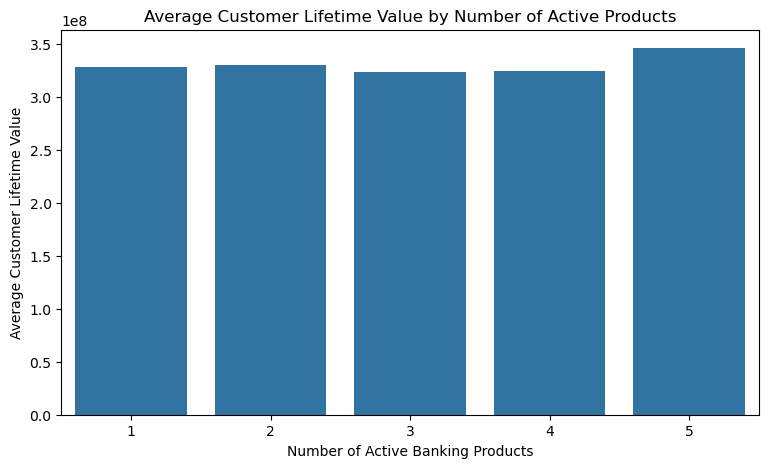

In [8]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=customers,
    x="active_products",
    y="customer_lifetime_value",
    estimator="mean",
    errorbar=None
)

plt.title("Average Customer Lifetime Value by Number of Active Products")

plt.xlabel("Number of Active Banking Products")

plt.ylabel("Average Customer Lifetime Value")

plt.show()

In [9]:
round(customers["active_products"].corr(
    customers["customer_lifetime_value"]), 4
)

np.float64(0.0012)

### Interpretation

Contrary to the initial hypothesis, no meaningful relationship was observed between the number of active banking products and Customer Lifetime Value (CLV). Although customers with five products exhibit a slightly higher average CLV, the differences across product groups are minimal, and the correlation between active products and CLV is approximately zero (0.001).

This suggests that, within this dataset, the breadth of a customer's product portfolio is not a reliable indicator of their estimated lifetime value.

### Business Insight

While product ownership is strongly associated with lower predicted churn probability, it does not appear to be associated with higher Customer Lifetime Value. These findings suggest that customer retention and customer value should be treated as related but distinct analytical concepts.

### Business Recommendation

The bank should avoid using the number of active products as the sole indicator of customer value. Instead, Customer Lifetime Value should continue to be evaluated using dedicated value metrics, while product ownership may be more useful as an indicator of customer retention.

### Limitation

Customer Lifetime Value is a derived variable provided within the dataset. The methodology used to calculate this metric is not available, limiting our ability to determine why it shows little association with product ownership.

###### Business Question
Is greater feature usage diversity associated with higher product satisfaction?

In [10]:
customers[
    ["feature_usage_diversity",
     "product_satisfaction"]
].describe().T

,count,mean,std,min,25%,50%,75%,max
feature_usage_diversity,48723.0,2.369538,1.744681,0.0,1.0,2.0,4.0,10.0
product_satisfaction,48723.0,0.473674,0.234457,0.0,0.4,0.4,0.6,1.0


In [11]:
correlation = customers["feature_usage_diversity"].corr(
    customers["product_satisfaction"]
)

print(f"Correlation: {correlation:.3f}")

Correlation: 0.668


In [12]:
feature_satisfaction = (
    customers
    .groupby("feature_usage_diversity", observed=True)
    .agg(
        Average_Product_Satisfaction=(
            "product_satisfaction",
            "mean"
        ),
        Customers=(
            "customer_id",
            "count"
        )
    )
    .round(2)
)

feature_satisfaction

,Average_Product_Satisfaction,Customers
feature_usage_diversity,,
0,0.20,7710
1,0.38,9429
2,0.47,10428
3,0.55,8922
4,0.62,6232
5,0.69,3563
6,0.75,1646
7,0.80,600
8,0.86,160


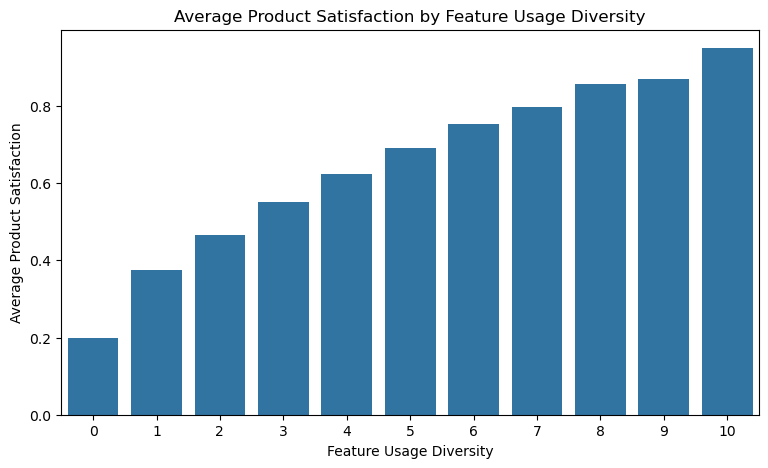

In [13]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=customers,
    x="feature_usage_diversity",
    y="product_satisfaction",
    estimator="mean",
    errorbar=None
)

plt.title("Average Product Satisfaction by Feature Usage Diversity")

plt.xlabel("Feature Usage Diversity")

plt.ylabel("Average Product Satisfaction")

plt.show()

### Interpretation
A clear positive relationship exists between feature usage diversity and product satisfaction.

Customers who use a wider range of digital banking features consistently report higher product satisfaction scores. Average satisfaction increases from **0.20** among customers who use no additional features to **0.95** among customers who use ten features.

This finding suggests that customers who engage more broadly with the bank's digital ecosystem also tend to perceive greater value from its products.

### Business Insight

Feature adoption appears to be strongly associated with customer satisfaction.

Customers who actively explore and use multiple banking features report substantially higher satisfaction levels than customers with limited feature usage. This suggests that encouraging customers to adopt more digital services may contribute to a more positive product experience.

### Business Recommendation
The bank should encourage greater adoption of digital banking features through targeted onboarding, in-app guidance, and personalized feature recommendations.

Customers with low feature usage diversity represent an opportunity for engagement campaigns designed to increase awareness and adoption of available digital services. Increasing feature adoption may contribute to higher customer satisfaction and stronger long-term customer relationships.

### Limitation

The analysis identifies a strong positive association between feature usage diversity and product satisfaction. However, the relationship should not be interpreted as causal.

It is possible that highly satisfied customers are more likely to explore additional features, or that other factors influence both feature adoption and satisfaction.

#### Business Question
Is higher customer satisfaction associated with higher Net Promoter Scores (NPS)?

##### Business Rationale
Net Promoter Score (NPS) is one of the most widely used indicators of customer loyalty and willingness to recommend a company's products or services.
Understanding the relationship between overall satisfaction and NPS helps determine whether improving customer experience is associated with stronger customer advocacy.

In [14]:
customers[
    ["satisfaction_score", "nps_score"]
].describe().T

,count,mean,std,min,25%,50%,75%,max
satisfaction_score,48723.0,4.162469,0.578473,2.0,4.0,4.0,5.0,6.0
nps_score,48723.0,-26.756850,12.560920,-80.0,-34.0,-28.0,-19.0,23.0


In [15]:
correlation = customers["satisfaction_score"].corr(
    customers["nps_score"]
)

print(f"Correlation: {correlation:.3f}")

Correlation: 0.917


In [16]:
nps_by_satisfaction = (
    customers
    .groupby("satisfaction_score", observed=True)
    .agg(
        Average_NPS=("nps_score", "mean"),
        Customers=("customer_id", "count")
    )
    .reset_index()
)

nps_by_satisfaction

,satisfaction_score,Average_NPS,Customers
0,2,-71.625000,16
1,3,-49.833005,4575
2,4,-30.004808,31823
3,5,-10.074163,12095
4,6,10.037383,214


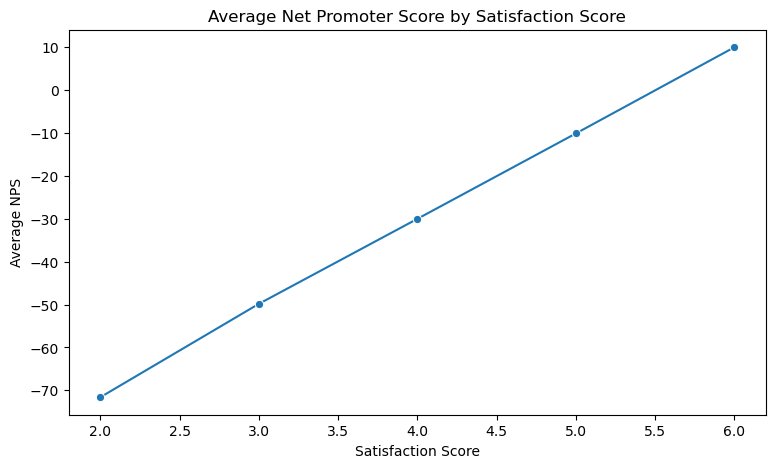

In [17]:
plt.figure(figsize=(9,5))

sns.lineplot(
    data=nps_by_satisfaction,
    x="satisfaction_score",
    y="Average_NPS",
    marker="o"
)

plt.title("Average Net Promoter Score by Satisfaction Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("Average NPS")

plt.show()

In [18]:
print(nps_by_satisfaction)

   satisfaction_score  Average_NPS  Customers
0                   2   -71.625000         16
1                   3   -49.833005       4575
2                   4   -30.004808      31823
3                   5   -10.074163      12095
4                   6    10.037383        214


### Interpretation
A strong positive relationship exists between customer satisfaction and Net Promoter Score (NPS), with a Pearson correlation coefficient of **0.917**.

As satisfaction scores increase, the average NPS improves consistently from **-71.63** among customers with the lowest recorded satisfaction score to **10.04** among those with the highest satisfaction score.

This indicates that customers reporting higher satisfaction are also substantially more likely to recommend the bank's products and services.

### Business Insight
Customer satisfaction appears to be a key indicator of customer advocacy.

The consistent increase in average NPS across satisfaction levels suggests that improvements in customer experience are associated with greater customer loyalty and willingness to recommend the bank.

### Business Recommendation
The bank should continue investing in initiatives that improve customer satisfaction, particularly those related to digital services, product quality, and customer support.

Since higher satisfaction is strongly associated with stronger customer advocacy, improving customer experience may also strengthen word-of-mouth marketing and long-term customer retention.

### Limitation
The highest and lowest satisfaction score categories contain relatively small numbers of customers compared to the middle satisfaction categories.

While the overall trend is strongly supported by the correlation analysis, the average NPS values at the extreme satisfaction levels should be interpreted with appropriate caution due to the smaller sample sizes.

##### Business Question
Is greater feature usage diversity associated with higher overall customer satisfaction?

In [19]:
correlation = customers["feature_usage_diversity"].corr(
    customers["satisfaction_score"]
)

print(f"Correlation: {correlation:.3f}")

Correlation: 0.063


In [20]:
satisfaction_by_feature = (
    customers
    .groupby("feature_usage_diversity", observed=True)
    .agg(
        Average_Satisfaction=("satisfaction_score", "mean"),
        Customers=("customer_id", "count")
    )
    .reset_index()
)

satisfaction_by_feature

,feature_usage_diversity,Average_Satisfaction,Customers
0,0,4.101038,7710
1,1,4.144660,9429
2,2,4.153529,10428
3,3,4.178099,8922
4,4,4.194641,6232
5,5,4.224530,3563
6,6,4.216889,1646
7,7,4.271667,600
8,8,4.287500,160
9,9,4.172414,29


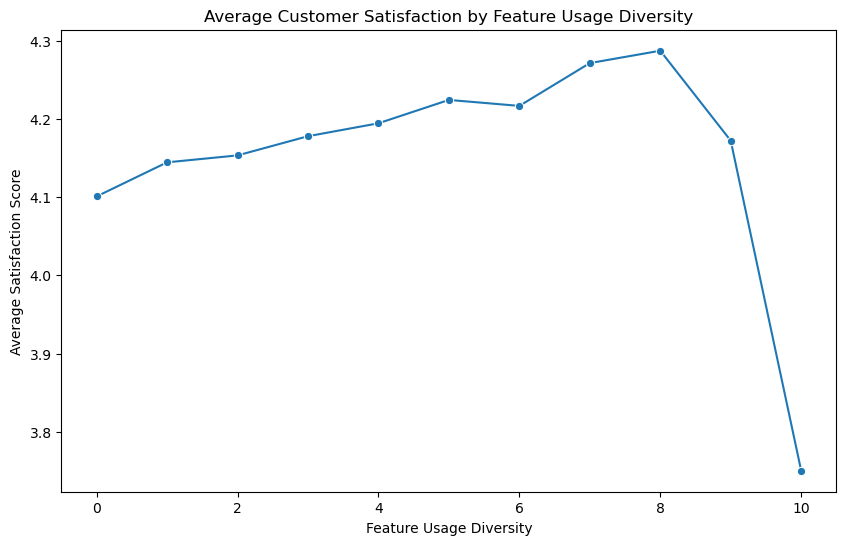

In [21]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data=satisfaction_by_feature,
    x="feature_usage_diversity",
    y="Average_Satisfaction",
    marker="o"
)

plt.title("Average Customer Satisfaction by Feature Usage Diversity")
plt.xlabel("Feature Usage Diversity")
plt.ylabel("Average Satisfaction Score")

plt.show()

### Interpretation

A weak positive relationship was observed between feature usage diversity and overall customer satisfaction (Pearson correlation = 0.063).

Average satisfaction scores generally increase as customers use a greater variety of digital banking features, rising from approximately **4.10** among customers with no feature usage diversity to approximately **4.29** among customers with a feature usage diversity score of eight. However, the overall increase is relatively small, indicating that feature usage alone does not strongly explain variations in overall customer satisfaction.

The decline observed at feature usage levels of nine and ten should be interpreted with caution due to the very small number of customers within these categories.

### Business Insight

While customers who use a wider range of digital banking features tend to report slightly higher overall satisfaction, feature usage diversity is not a strong predictor of overall customer satisfaction.

This suggests that overall satisfaction is likely influenced by a broader combination of factors, including customer support, transaction experience, product quality, pricing, and service reliability, rather than digital feature adoption alone.

### Business Recommendation

The bank should continue encouraging customers to adopt digital banking features, as increased feature usage is associated with improved product satisfaction. However, initiatives aimed at improving overall customer satisfaction should adopt a broader customer experience strategy that includes service quality, customer support, and transaction reliability in addition to digital feature development.

### Limitation

Although a slight upward trend is observed, the relationship between feature usage diversity and overall customer satisfaction is weak. In addition, the highest feature usage categories contain relatively few customers, limiting the reliability of the average satisfaction scores for those groups.

Consequently, these findings should be interpreted as descriptive associations rather than evidence of a strong relationship.

## Executive Summary

This analysis examined the factors associated with customer value, digital engagement, and customer experience within the bank.

The strongest finding indicates that customers with a greater number of active banking products exhibit substantially lower predicted churn probabilities, suggesting that deeper banking relationships are associated with stronger customer retention.

Digital engagement also appears to play an important role in shaping customer perceptions of the bank's products. Customers who use a wider range of digital banking features report considerably higher product satisfaction. However, feature usage demonstrates only a weak relationship with overall customer satisfaction, indicating that broader aspects of the customer experience contribute to overall perceptions of the bank.

Customer satisfaction emerged as one of the strongest indicators of customer advocacy. A very strong positive relationship was observed between customer satisfaction and Net Promoter Score, suggesting that improvements in customer experience are associated with increased customer loyalty and willingness to recommend the bank.

Finally, although customers with more banking products exhibit lower predicted churn probabilities, no meaningful relationship was observed between product ownership and Customer Lifetime Value. This suggests that customer retention and customer value should be evaluated as related but distinct business objectives.

## Strategic Recommendations

Based on the findings of this analysis, the following recommendations are proposed:

1. Strengthen cross-selling initiatives to encourage customers to adopt additional banking products, as greater product adoption is associated with lower predicted churn probability.

2. Increase customer awareness and adoption of digital banking features through onboarding campaigns and in-app guidance to enhance product satisfaction.

3. Continue investing in customer experience initiatives, including service quality and customer support, as improvements in customer satisfaction are strongly associated with higher customer advocacy.

4. Evaluate Customer Lifetime Value independently from product ownership when identifying high-value customers, as product adoption alone does not appear to predict customer value.

In [ ]:
import streamlit as st

In [ ]:
!streamlit run ../app.py